In [ ]:
                                          TP 2 : Apprentissage Profond avec TensorFlow / Keras  

Ensemble, ils offrent puissance et facilité d’utilisation. Exercice 1 : Reconnaissance de chiffres manuscrits (MNIST) 

1Import des bibliothèques 

In [3]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
print("TensorFlow :", tf.__version__)

TensorFlow : 2.22.0-rc0


question 1 :TensorFlow est une bibliothèque Python open source utilisée notamment pour créer, entraîner et déployer des modèles de Machine Learning et de Deep Learning.
Keras est une API de haut niveau intégrée à TensorFlow via tf.keras. Elle simplifie la création et l'entraînement des réseaux de neurones.

question 2: La couche Flatten transforme une image bidimensionnelle (28 × 28) en un vecteur unidimensionnel 
de 784 valeurs, afin de pouvoir l'envoyer aux couches Dense.

question 3 : la version de TensorFlow installée sur ma machine est  2.22.0-rc0

question 4 : La couche Flatten transforme les données en un vecteur unidimensionnel. Les couches Dense traitent ces valeurs à l'aide de neurones connectés aux entrées de la couche précédente, en utilisant des poids et des biais. La couche cachée apprend des caractéristiques utiles, tandis que la couche de sortie produit les prédictions. Sequential permet d'organiser les couches dans l'ordre souhaité.

2. Chargement et préparation du dataset 

In [6]:
(x_train, y_train), (x_test, y_test) = (
    keras.datasets.mnist.load_data()
)
#NORMALISATION
x_train=x_train/255
x_test=x_test/255
print("Images d'entraînement :", x_train.shape)
print("Labels d'entraînement :", y_train.shape)

Images d'entraînement : (60000, 28, 28)
Labels d'entraînement : (60000,)


question 1: Dans MNIST, chaque pixel possède une valeur comprise entre 0 et 255 0 pour le noir et 255 pour le blanc et entre les deux il y a différent 
nuance du gris donc on divise par 255 pour rammener tous les valeurs à un même echelle entre 0 et 1 et cela Faciliter l'apprentissage du réseau de neurones et Favoriser une convergence plus rapide et plus stable.
question 2 :la taille d'une image est 28 pixcel fois 28 pixcel ce qui fait 784 pixcel.
question 2: ce jeu d'entrainement contient 60000*28*28 = valeur

3. Visualisation d’échantillons 

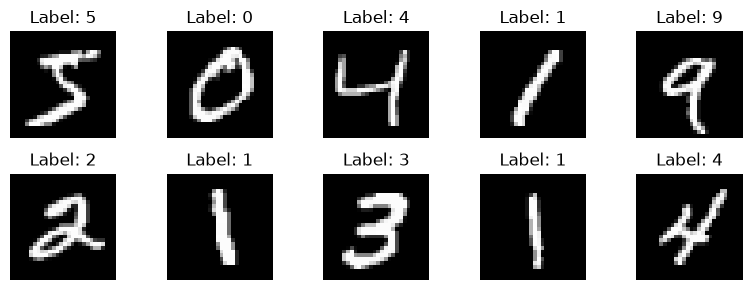

In [10]:
plt.figure(figsize=(8, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

question 1: on peut changer le nombre des images affichée seulment par le changement de range () c'est lui le responsable de géneration des 10 images
car il est passé en argument à plt.subplot .
question 2:cmap signifie colormap (palette de couleurs et 
'gray' signifie que l’image sera affichée en niveaux de gris, du noir au blanc.
question 3: cette étape est importante car on peut voir les entrées et les labels pour savoir qu'est ce que notre model doit prédir .

In [20]:
from tensorflow.keras.layers import Input, Flatten, Dense 
model = keras.Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

question 1: ce modèle contient 101,770 modèle .
question 2: le fonction d'activation utilisé dans la couche de sortie est Softmax ,elle transforme les 10 scores de sortie en 10 probabilités, une pour
chaque chiffre de 0 à 9.
question 3:ReLU aide le réseau à apprendre, tandis que Softmax permet de calculer les probabilités des classes prédites.
ReLU(x)=max(0,x)
Elle applique une règle simple :
- Si (x) est négatif, le résultat est (0).
- Si (x) est positif, le résultat est (x).

In [22]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

question 1: un optimisateur est un algorithme qui essaie de trouver les meilleurs paramètres ou les paramètres optimiser pour diminuer le coût et l'erreur afin d'obtenir les meilleures prédiction.
question 2:La fonction de perte mesure l'écart entre les prédictions du modèle et les valeurs réelles. Elle fournit une valeur numérique que l'optimiseur cherche à minimiser pendant l'entraînement.
question 3:si on change la fonction de perte on peut avoir une nouvelle valeur qui quantifie la différence entre les valeurs réelles et les valeur prédites.Mais ce n'est pas seulement la valeur qui change : la manière dont l'erreur est mesurée change aussi. Cela peut modifier les mises à jour des paramètres et donc les résultats de l'entraînement
question 4:un mauvais choix d'un optimisateur donne des paramètres non optimiser et par suite une grande perte et des mauvaise prédictions.
question 5:La fonction de perte mesure l'erreur selon une formule mathématique. L'optimiseur utilise cette information pour ajuster les poids et les biais.Les métriques permettent de suivre et d'évaluer les performances du modèle pendant l'entraînement et lors de l'évaluation.

In [23]:
history=model.fit(
x_train,y_train,
epochs=5,
batch_size=32,
validation_data=(x_test,y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9269 - loss: 0.2553 - val_accuracy: 0.9602 - val_loss: 0.1348
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9669 - loss: 0.1108 - val_accuracy: 0.9703 - val_loss: 0.0959
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9778 - loss: 0.0754 - val_accuracy: 0.9739 - val_loss: 0.0824
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9835 - loss: 0.0554 - val_accuracy: 0.9755 - val_loss: 0.0792
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9884 - loss: 0.0408 - val_accuracy: 0.9777 - val_loss: 0.0762


question 1: Une époque correspond à un passage complet du modèle sur l'ensemble des données d'entraînement.1 époque : le modèle parcourt les 60 000 images une fois.
5 époques : le modèle parcourt les 60 000 images cinq fois.
50 époques : le modèle parcourt les 60 000 images cinquante fois.
question 2:Le jeu de validation permet de vérifier si le modèle apprend à bien généraliser à des données qu'il n'utilise pas directement pour ajuster ses poids.
question 3:Plusieurs situations sont possibles :
- Amélioration : le modèle dispose de davantage de passages pour apprendre et ses performances peuvent augmenter.
- Stabilisation : les performances finissent par peu évoluer.
- Surapprentissage : le modèle mémorise trop les données d'entraînement et généralise moins bien sur de nouvelles données.

In [24]:
test_loss,test_acc = model.evaluate(x_test,y_test)
print(f"Test accuracy :{test_acc:.4f}")
print(f"Test loss:{test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9777 - loss: 0.0762
Test accuracy :0.9777
Test loss:0.0762


question 1: la precision final du modèle est très bonne Test accuracy :0.9777 et pour le loss function Test loss:0.0762 est très petite ce qui indique
que ce modèle à pu généraliser sur des nouvelles données.
question 2:souvent la précision du modèle est inférieur à celle d'entraînement puisque le modèle n'a jamais vue les données de test par contre il s'est entraîner plusier fois sur les données d'entraînement.
question 3:Réduire le nombre d'époques pour éviter un entraînement trop long.
Utiliser l'Early Stopping pour arrêter l'entraînement lorsque les performances de validation ne s'améliorent plus.
Ajouter de la régularisation, par exemple avec Dropout, pour limiter la dépendance excessive à certaines caractéristiques.
Augmenter la quantité de données d'entraînement ou utiliser la data augmentation pour créer des variations réalistes des images.
Réduire la complexité du modèle s'il est trop grand par rapport aux données disponibles.

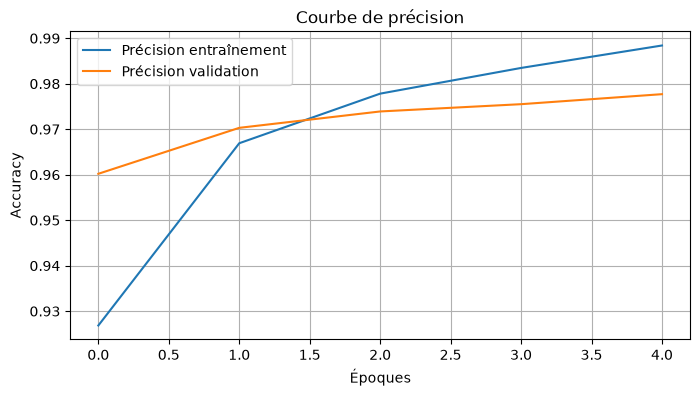

In [25]:
plt.figure(figsize=(8,4))
plt.plot(history.history['accuracy'], label='Précision entraînement')
plt.plot(history.history['val_accuracy'], label='Précision validation')
plt.title('Courbe de précision')
plt.xlabel('Époques')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

question 1:on remarque que la précision pendant l'entraînement est plus grande que celle de validation.
question 2:Si la précision d'entraînement continue d'augmenter alors que celle de validation stagne ou diminue, cela peut indiquer un surapprentissage.
Le modèle apprend alors très bien les données d'entraînement, mais généralise moins bien aux données de validation.
question 3:pour remédier au problème de surapprentissage il faut :Réduire le nombre d'époques pour éviter un entraînement trop long.
Utiliser l'Early Stopping pour arrêter l'entraînement lorsque les performances de validation ne s'améliorent plus.
Ajouter de la régularisation, par exemple avec Dropout, pour limiter la dépendance excessive à certaines caractéristiques.
Augmenter la quantité de données d'entraînement ou utiliser la data augmentation pour créer des variations réalistes des images.
Réduire la complexité du modèle s'il est trop grand par rapport aux données disponibles.
question 4: si les deux courbe divèrge c-à-dSi la précision d'entraînement augmente tandis que celle de validation diminue ou stagne, il faut suspecter un surapprentissage.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


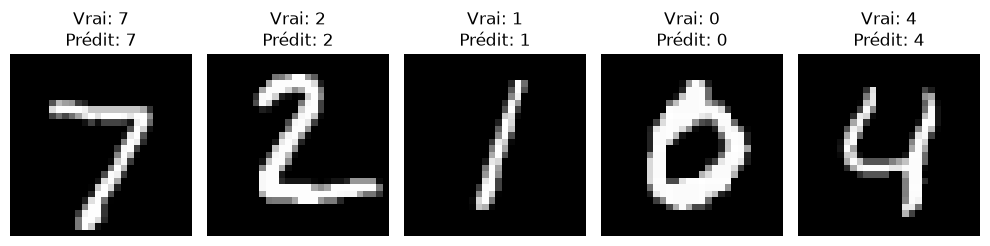

In [26]:
predictions = model.predict(x_test)

plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

question 1:sur les 5 images affichées, le modèle ne commet aucune erreur : la classe prédite correspond à la vraie classe pour chacune.Cela ne prouve pas que le modèle est parfait, car seules 5 images ont été testées et l’accuracy sur tout le jeu de test donne une meilleure idée.
question 2: on peut l'expliquer par un mal entraînement soit par manque de données ou par une mal opptimisation des parmètres ou un surapprentissage 
question 3:Le réseau actuel (de type MLP, avec des couches Dense) aplatit l’image en un vecteur, ce qui fait perdre l’information spatiale : il ne sait pas que deux pixels voisins sont liés. Un réseau de neurones convolutif (CNN) corrige ce problème :
Les couches de convolution détectent des motifs locaux (bords, courbes, formes) grâce à des filtres partagés sur toute l’image.
Les couches de pooling réduisent la taille des cartes de caractéristiques et rendent le modèle plus robuste aux petits décalages ou déformations.
Le nombre de paramètres est plus faible que dans un réseau entièrement connecté, ce qui limite le risque de surapprentissage.
je propose aussi:
Data augmentation : rotations, translations et zooms légers pour enrichir les données d’entraînement.
Dropout et régularisation pour réduire le surapprentissage.
Réglage des hyperparamètres (taux d’apprentissage, nombre d’époques, taille du batch, nombre de neurones).
Normalisation des données et Batch Normalization pour stabiliser l’entraînement.